# Standard TCT vs Adaptive TCT

Compares the two TCT accountants at a **predetermined number of tops τ**.

| Accountant | Charge per user | Requires τ upfront? |
|---|---|---|
| Standard TCT | K_τ · ε once at registration | Yes |
| Adaptive TCT (non-independent) | K_1·ε at registration + increments per top | No |

**Non-independent mode:** ChargeTargetHit fires for every registered user whenever any
top occurs, regardless of individual contribution.  This is a fair comparison to
Standard TCT, which also charges all registered users on registration.

**Sections:**
1. Theoretical cost curves — K_τ for both accountants vs τ
2. Single-user budget trace — how each accountant drains budget for one user
3. Budget remaining at the τ-th hit — sweep over τ
4. Population simulation — average budget remaining across the full population

In [1]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import matplotlib.pyplot as plt

from simulation.population import User
from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_tct import StandardTCTAccountant
from simulation.calibration import q_from_epsilon, set_threshold_for_hit_rate
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.environment import SimulationEnvironment

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

In [2]:
EPSILON = 0.1
DELTA   = 1e-3
TAU_MAX = 50

q = q_from_epsilon(EPSILON)
print(f'ε={EPSILON}, δ={DELTA}, q={q:.4f} (Lemma 2.3)')

ε=0.1, δ=0.001, q=0.4750 (Lemma 2.3)


## Section 1: Theoretical Cost Curves

For each predetermined τ, how many compositions (and how much ε) does each accountant charge?

- **Standard TCT**: K_τ^{standard} · ε upfront (uses full δ on one target)  
- **Adaptive TCT**: K_{τ+1}^{adaptive} · ε total after τ actual tops (splits δ via Zeta-2)

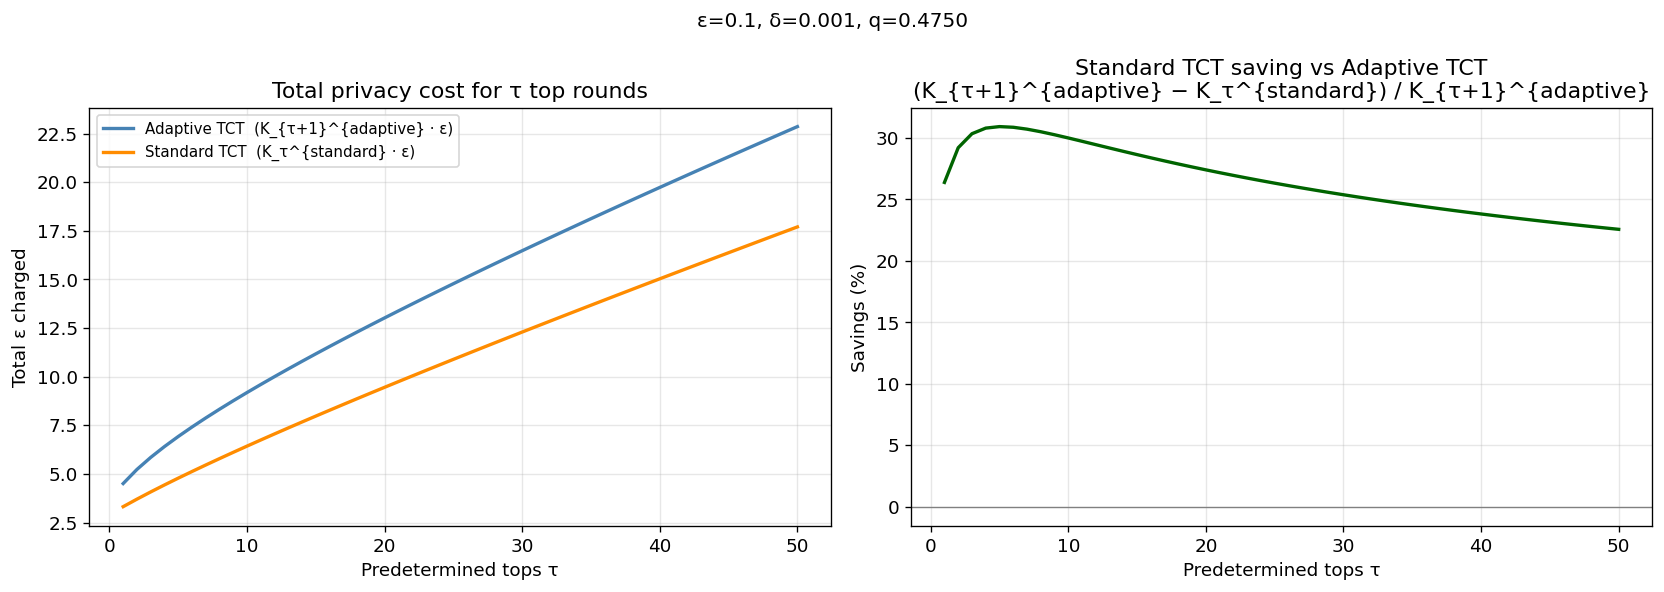

   τ    Adaptive ε    Standard ε    Saving
------------------------------------------
   1         4.504         3.316     26.4%
   2         5.230         3.703     29.2%
   5         6.922         4.782     30.9%
  10         9.185         6.429     30.0%
  20        13.023         9.454     27.4%
  50        22.859        17.701     22.6%


In [3]:
tau_vals = list(range(1, TAU_MAX + 1))

def K_standard(tau, epsilon=EPSILON, delta=DELTA):
    q = q_from_epsilon(epsilon)
    beta = math.log(1.0 / delta)
    alpha = (beta + math.sqrt(beta**2 + 2*beta*tau)) / tau
    return (1 + alpha) / q * tau

def K_adaptive_after_tau(tau, epsilon=EPSILON, delta=DELTA):
    acc = AdaptiveTCTAccountant(epsilon=epsilon, delta=delta, independent=False)
    return acc.compositions(tau + 1)

K_std  = [K_standard(t) * EPSILON          for t in tau_vals]
K_adap = [K_adaptive_after_tau(t) * EPSILON for t in tau_vals]

savings = [(K_adap[i] - K_std[i]) / K_adap[i] * 100 for i in range(len(tau_vals))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(tau_vals, K_adap, color='steelblue',  lw=2, label='Adaptive TCT  (K_{τ+1}^{adaptive} · ε)')
ax.plot(tau_vals, K_std,  color='darkorange', lw=2, label='Standard TCT  (K_τ^{standard} · ε)')
ax.set_xlabel('Predetermined tops τ')
ax.set_ylabel('Total ε charged')
ax.set_title('Total privacy cost for τ top rounds')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(tau_vals, savings, color='darkgreen', lw=2)
ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel('Predetermined tops τ')
ax.set_ylabel('Savings (%)')
ax.set_title('Standard TCT saving vs Adaptive TCT\n(K_{τ+1}^{adaptive} − K_τ^{standard}) / K_{τ+1}^{adaptive}')
ax.grid(True, alpha=0.3)

plt.suptitle(f'ε={EPSILON}, δ={DELTA}, q={q:.4f}', fontsize=12)
plt.tight_layout()
plt.show()

print(f'{"τ":>4}  {"Adaptive ε":>12}  {"Standard ε":>12}  {"Saving":>8}')
print('-' * 42)
for t in [1, 2, 5, 10, 20, 50]:
    j = t - 1
    print(f'{t:>4}  {K_adap[j]:>12.3f}  {K_std[j]:>12.3f}  {savings[j]:>7.1f}%')

## Section 2: Single-User Budget Trace

Trace one user's budget over time under each accountant, for a fixed τ.
Tops occur every `HIT_EVERY` rounds (deterministic for clarity).

Standard TCT makes one large upfront payment then flatlines.  
Adaptive TCT steps down at each top.

τ=10, ε=0.1, δ=0.001, q=0.4750
Standard TCT registration cost: 6.4295ε  (K_τ=64.3)
Adaptive TCT after τ tops:      9.1847ε  (K_{τ+1}=91.8)
Budget: 20.0ε


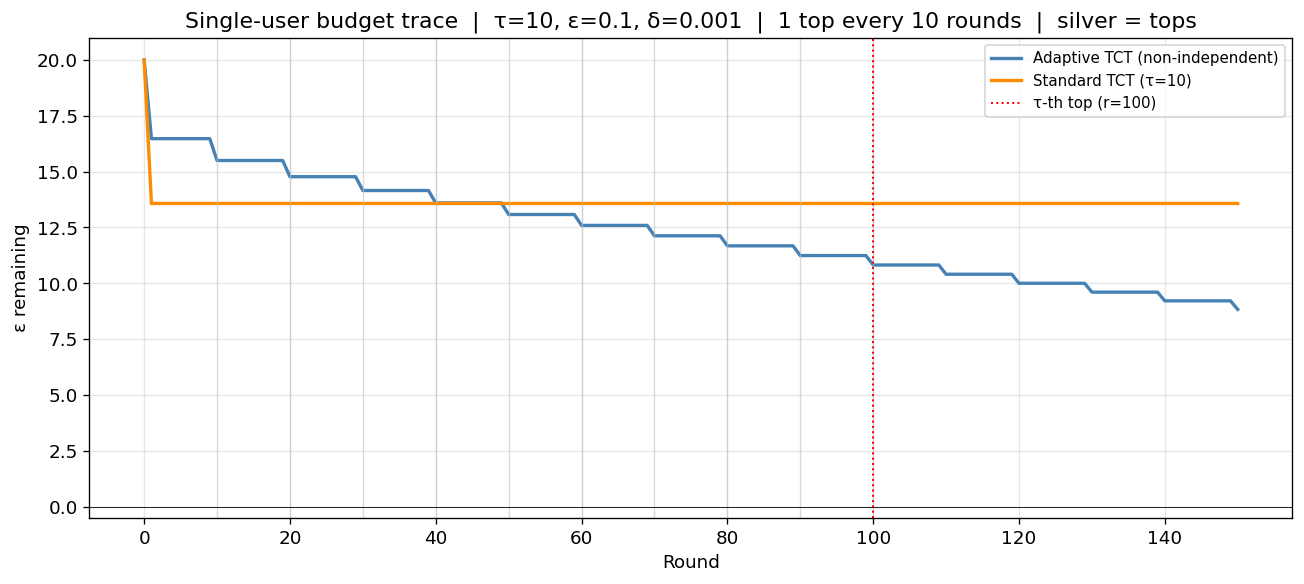


At round 100 (τ-th top):
  Standard TCT remaining: 13.571ε
  Adaptive TCT remaining: 10.815ε


In [4]:
TAU        = 10
HIT_EVERY  = 10
N_ROUNDS   = TAU * HIT_EVERY + 50
EPS_BUDGET = 20.0

acc_std  = StandardTCTAccountant(epsilon=EPSILON, delta=DELTA, tau=TAU)
acc_adap = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA, independent=False)

print(f'τ={TAU}, ε={EPSILON}, δ={DELTA}, q={q:.4f}')
print(f'Standard TCT registration cost: {acc_std.K_tau * EPSILON:.4f}ε  (K_τ={acc_std.K_tau:.1f})')
print(f'Adaptive TCT after τ tops:      {acc_adap.compositions(TAU+1)*EPSILON:.4f}ε  (K_{{τ+1}}={acc_adap.compositions(TAU+1):.1f})')
print(f'Budget: {EPS_BUDGET}ε')

def trace(acc):
    user = User(user_id=0, epsilon_budget=EPS_BUDGET, delta_budget=1.0, conversion_rate=0.0)
    remaining = [EPS_BUDGET]
    for r in range(1, N_ROUNDS + 1):
        is_top = (r % HIT_EVERY == 0)
        e, d = acc.charge(user, is_top=is_top, contributed=is_top, round_num=r)
        user.epsilon_spent += e
        user.delta_spent   += d
        remaining.append(max(user.epsilon_remaining, 0.0))
    return remaining

rem_std  = trace(acc_std)
rem_adap = trace(acc_adap)

rounds     = list(range(N_ROUNDS + 1))
hit_rounds = [r for r in range(1, N_ROUNDS + 1) if r % HIT_EVERY == 0]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(rounds, rem_adap, color='steelblue',  lw=2, label='Adaptive TCT (non-independent)')
ax.plot(rounds, rem_std,  color='darkorange', lw=2, label=f'Standard TCT (τ={TAU})')
for h in hit_rounds[:TAU]:
    ax.axvline(h, color='silver', lw=0.8, alpha=0.6)
ax.axvline(TAU * HIT_EVERY, color='red', lw=1.2, linestyle=':', label=f'τ-th top (r={TAU*HIT_EVERY})')
ax.axhline(0, color='black', lw=0.5)
ax.set_xlabel('Round')
ax.set_ylabel('ε remaining')
ax.set_ylim(-0.5, EPS_BUDGET * 1.05)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_title(
    f'Single-user budget trace  |  τ={TAU}, ε={EPSILON}, δ={DELTA}  |  '
    f'1 top every {HIT_EVERY} rounds  |  silver = tops'
)
plt.tight_layout()
plt.show()

tau_round = TAU * HIT_EVERY
print(f'\nAt round {tau_round} (τ-th top):')
print(f'  Standard TCT remaining: {rem_std[tau_round]:.3f}ε')
print(f'  Adaptive TCT remaining: {rem_adap[tau_round]:.3f}ε')

## Section 3: Sweep over τ — Budget Remaining at the τ-th Top

For each τ, how much budget is left after τ tops have occurred?
This directly answers: *for a given number of tops, which accountant preserves more budget?*

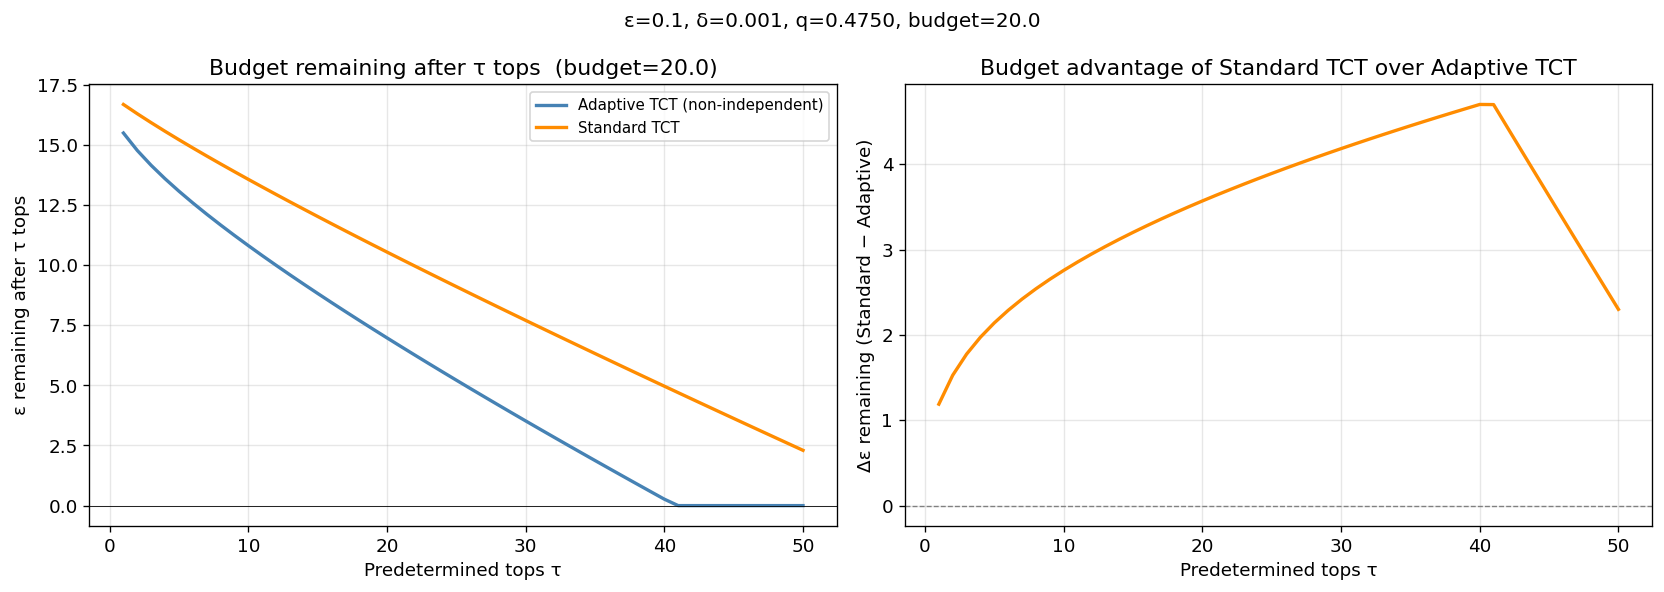

   τ   Adaptive rem   Standard rem    Std−Adap
----------------------------------------------
   1         15.496         16.684      +1.188
   2         14.770         16.297      +1.527
   5         13.078         15.218      +2.141
  10         10.815         13.571      +2.755
  20          6.977         10.546      +3.569
  50          0.000          2.299      +2.299


In [5]:
EPS_BUDGET = 20.0
tau_sweep  = list(range(1, TAU_MAX + 1))

def budget_after_tau_tops(tau, accountant_factory):
    acc  = accountant_factory(tau)
    user = User(user_id=0, epsilon_budget=EPS_BUDGET, delta_budget=1.0, conversion_rate=0.0)
    e, d = acc.charge(user, is_top=False, contributed=False, round_num=1)
    user.epsilon_spent += e; user.delta_spent += d
    for k in range(1, tau + 1):
        e, d = acc.charge(user, is_top=True, contributed=True, round_num=k + 1)
        user.epsilon_spent += e; user.delta_spent += d
    return max(user.epsilon_remaining, 0.0)

rem_std_sweep  = [budget_after_tau_tops(t, lambda t: StandardTCTAccountant(EPSILON, DELTA, t))
                  for t in tau_sweep]
rem_adap_sweep = [budget_after_tau_tops(t, lambda _: AdaptiveTCTAccountant(EPSILON, DELTA, independent=False))
                  for t in tau_sweep]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(tau_sweep, rem_adap_sweep, color='steelblue',  lw=2, label='Adaptive TCT (non-independent)')
ax.plot(tau_sweep, rem_std_sweep,  color='darkorange', lw=2, label='Standard TCT')
ax.axhline(0, color='black', lw=0.5)
ax.set_xlabel('Predetermined tops τ')
ax.set_ylabel('ε remaining after τ tops')
ax.set_title(f'Budget remaining after τ tops  (budget={EPS_BUDGET})')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
diff = [rem_std_sweep[i] - rem_adap_sweep[i] for i in range(len(tau_sweep))]
ax.plot(tau_sweep, diff, color='darkorange', lw=2)
ax.axhline(0, color='gray', lw=0.8, linestyle='--')
ax.set_xlabel('Predetermined tops τ')
ax.set_ylabel('Δε remaining (Standard − Adaptive)')
ax.set_title('Budget advantage of Standard TCT over Adaptive TCT')
ax.grid(True, alpha=0.3)

plt.suptitle(f'ε={EPSILON}, δ={DELTA}, q={q:.4f}, budget={EPS_BUDGET}', fontsize=12)
plt.tight_layout()
plt.show()

print(f'{"τ":>4}  {"Adaptive rem":>13}  {"Standard rem":>13}  {"Std−Adap":>10}')
print('-' * 46)
for t in [1, 2, 5, 10, 20, 50]:
    j = t - 1
    print(f'{t:>4}  {rem_adap_sweep[j]:>13.3f}  {rem_std_sweep[j]:>13.3f}  {diff[j]:>+10.3f}')